In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

df = pd.read_csv("../amz_uk_price_prediction_dataset.csv")

display(df.head())
df.shape

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


(2443651, 9)

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [2]:
frequency_table_category = df["category"].value_counts()
top5 = frequency_table_category.head(5)
top5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

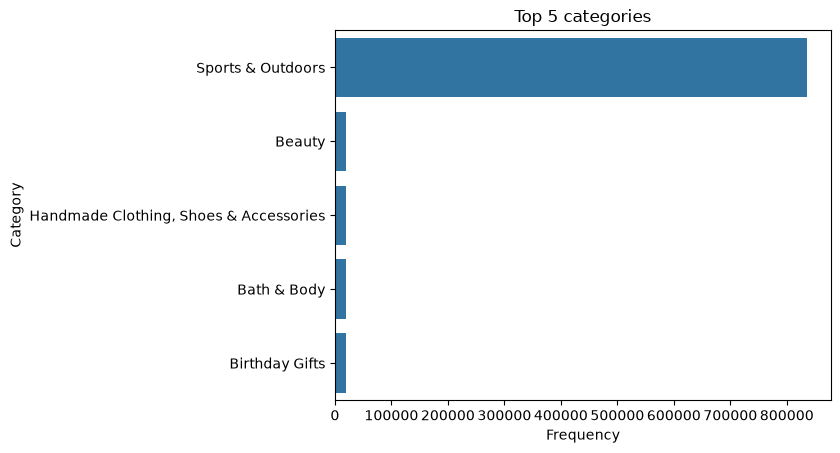

In [3]:
sns.barplot(x=top5.values, y=top5.index)
plt.xlabel("Frequency")
plt.ylabel("Category")
plt.title("Top 5 categories")
plt.show()

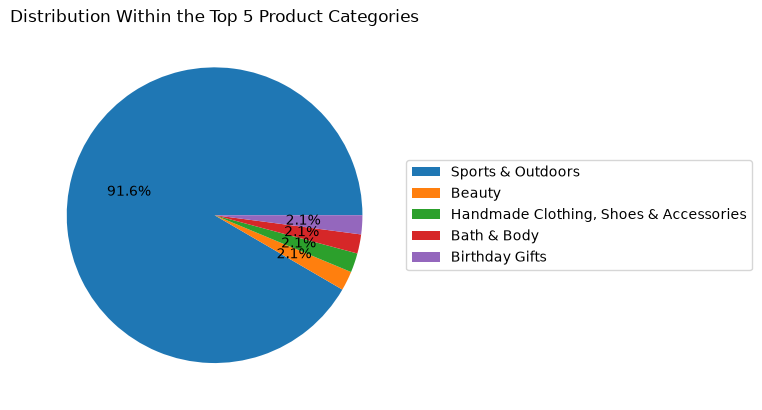

In [4]:
top5.plot.pie(autopct='%1.1f%%', labels=None)
plt.legend(labels=top5.index, loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Distribution Within the Top 5 Product Categories")
plt.show()

Sports & Outdoors dominate the listings.

### Part 2: Delving into Product Pricing
**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?


1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [5]:
print("Mean price:", df["price"].mean().round(2))
print("\nMedian price:", df["price"].median().round(2))
print("\nMode:", df["price"].mode()[0].round(2))

Mean price: 89.24

Median price: 19.09

Mode: 9.99


*Answer:*
The average price point is 89.24£, which is almost 9 times higher than the most common price point.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [6]:
# Variance
variance = df["price"].var()

# Standard deviation
std = df["price"].std()

# Range
price_range = df["price"].max() - df["price"].min()

# Interquartile range
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1

print("Variance:", round(variance, 2))
print("Standard deviation:", round(std, 2))
print("Range:", round(price_range, 2))
print("IQR:", round(iqr, 2))

Variance: 119445.49
Standard deviation: 345.61
Range: 100000.0
IQR: 36.0


Product prices have a very large overall range, but the IQR is relatively small. This suggests that most products have prices within a narrower range, while a few extremely expensive products may be outliers. These outliers are likely increasing the variance and standard deviation.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [7]:
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df["price"] < lower_bound) | (df["price"] > upper_bound)]

print("Number of outliers:", len(outliers))

Number of outliers: 327688


In [8]:
outlier_percentage = (len(outliers) / len(df)) * 100

print("Percentage of outliers:", round(outlier_percentage, 2), "%")

Percentage of outliers: 13.41 %


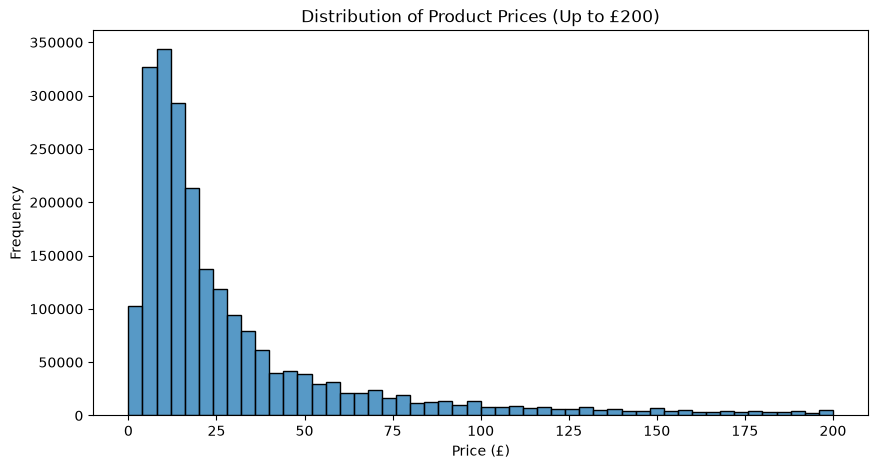

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(df[df["price"] <= 200]["price"], bins=50)
plt.title("Distribution of Product Prices (Up to £200)")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")
plt.show()

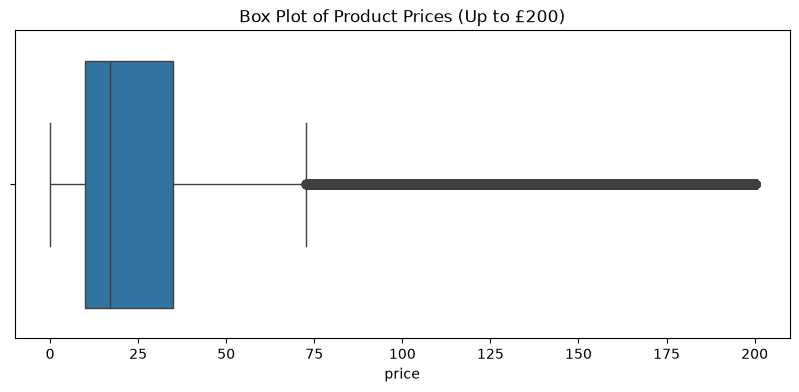

In [10]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[df["price"] <= 200]["price"])
plt.title("Box Plot of Product Prices (Up to £200)")
plt.show()

Most products are relatively inexpensive, with a median price of £19.09 and a mode of £9.99.

The distribution is strongly right-skewed, with some extremely expensive products increasing the mean price to £89.24.

Approximately 13.41% of products are identified as potential outliers using the IQR method. These extreme values make the original histogram and box plot difficult to interpret.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [11]:
print("Mean rating:", round(df["stars"].mean(), 2))
print("Median rating:", round(df["stars"].median(), 2))
print("Mode rating:", df["stars"].mode()[0])

Mean rating: 2.15
Median rating: 0.0
Mode rating: 0.0


The average product rating is 2.15, while both the median and mode are 0. This suggests that many products have a rating of 0, which may indicate that they have not received customer reviews yet.

We should investigate these zero ratings before drawing conclusions about customer satisfaction.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [12]:
rating_variance = df["stars"].var()
rating_std = df["stars"].std()

rating_q1 = df["stars"].quantile(0.25)
rating_q3 = df["stars"].quantile(0.75)
rating_iqr = rating_q3 - rating_q1

print("Variance:", round(rating_variance, 2))
print("Standard deviation:", round(rating_std, 2))
print("IQR:", round(rating_iqr, 2))

Variance: 4.82
Standard deviation: 2.19
IQR: 4.4


Product ratings show considerable variation, with a standard deviation of 2.19 and an IQR of 4.4.

This suggests that ratings are widely spread across the dataset. However, the large number of 0-star ratings may be influencing these results, as some products might not have received any reviews.

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [13]:
rating_skewness = df["stars"].skew()
rating_kurtosis = df["stars"].kurt()

print("Skewness:", round(rating_skewness, 2))
print("Kurtosis:", round(rating_kurtosis, 2))

Skewness: 0.08
Kurtosis: -1.93


The skewness of 0.08 indicates that product ratings are almost symmetrical, with very little skewness.

The kurtosis of -1.93 suggests a flatter distribution with lighter tails than a normal distribution.

However, the large number of 0-star ratings may affect the distribution, so these results should be interpreted carefully.

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

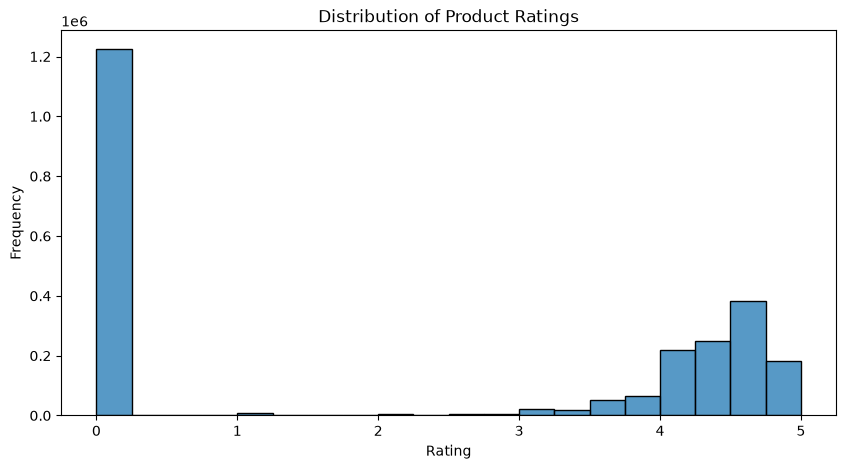

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(df["stars"], bins=20)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

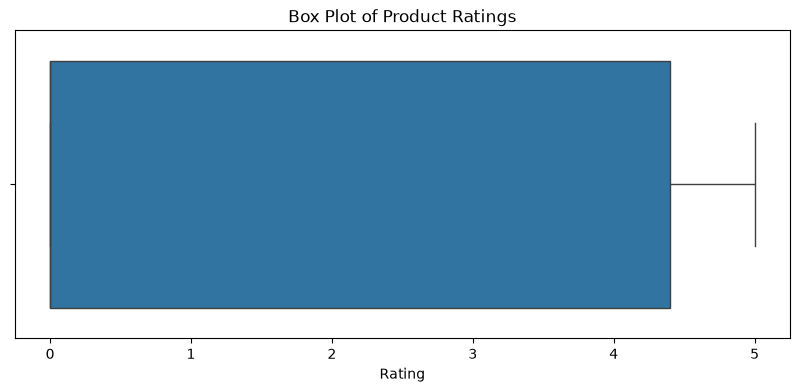

In [15]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["stars"])
plt.title("Box Plot of Product Ratings")
plt.xlabel("Rating")
plt.show()

The histogram shows that 0-star ratings are very common, which may indicate that many products have not received ratings yet.

The remaining ratings are mostly concentrated around higher values, particularly 4 to 5 stars.

The box plot shows a wide spread of ratings, influenced by the large number of zero values.

Overall, the distribution is not normal, and zero ratings should be investigated before making conclusions about customer satisfaction.